# Proyecto de Visualización — Práctica Individual
**Bootcamp Python PY4 · Módulo 1 · Semana 4**

---

Este notebook es tu espacio de trabajo para el proyecto de cierre del módulo.
A diferencia de las sesiones anteriores, aquí tú tomas las decisiones:
qué datos explorar, qué preguntas hacer, y qué historia contar.

El trabajo se organiza en cuatro etapas:

1. Selección y carga de datos
2. Análisis exploratorio (EDA)
3. Estrategia de visualización con apoyo de IA
4. Construcción de las tres visualizaciones con narrativa

**Entrega:** un único archivo `.ipynb` que corre sin errores de principio a fin.


## 1. Setup

Importa todas las librerías que vas a necesitar en esta celda.
Si necesitas instalar algo, hazlo aquí también.


In [51]:
# Instalación
!pip install -q "vegafusion[embed]>=1.5.0"
!pip install -q "vl-convert-python>=1.6.0"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import altair as alt

alt.data_transformers.enable("vegafusion")

sns.set_theme(style="white", palette="muted")
plt.rcParams["figure.dpi"] = 120

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


---
## 2. Selección y carga de datos

Elige uno de los tres datasets disponibles, o trae el tuyo propio.
Lee la descripción de cada uno antes de decidir.

---

### Opción A — Video Games
Ventas y puntuaciones de videojuegos entre 1977 y 2023.
Contiene: título, consola, género, publisher, puntuación de crítica,
ventas por región (Norteamérica, Japón, Europa, otros) y fecha de lanzamiento.
Preguntas posibles: ¿qué géneros venden más? ¿hay diferencias regionales?
¿existe relación entre la puntuación y las ventas?

```python
BASE_URL = "https://raw.githubusercontent.com/Camille-Le-Roy/data_analytics_resources/main/"
df = pd.read_csv(BASE_URL + "video_game_dataset.csv")
```

---

### Opción B — Olympics
Resultados de los Juegos Olímpicos de 1896 a 2016.
Contiene: nombre del atleta, sexo, edad, altura, peso, país, deporte,
evento y medalla obtenida.
Preguntas posibles: ¿cómo ha evolucionado la participación femenina?
¿qué países dominan ciertos deportes? ¿existe relación entre el físico y el deporte?

```python
BASE_URL = "https://raw.githubusercontent.com/Camille-Le-Roy/data_analytics_resources/main/"
df = pd.read_csv(BASE_URL + "olympic_dataset.csv")
```

---

### Opción C — Coffee Shop Sales
Transacciones de una cadena de cafeterías en Nueva York durante 2023.
Contiene: fecha, hora, ubicación, producto, categoría, cantidad y precio.
Preguntas posibles: ¿cuáles son los productos más vendidos? ¿hay patrones
por hora del día o día de la semana? ¿qué tienda genera más ingresos?

```python
BASE_URL = "https://raw.githubusercontent.com/Camille-Le-Roy/data_analytics_resources/main/"
df = pd.read_csv(BASE_URL + "coffee_shop_sales_dataset.csv")
```

---

### Opción D — Dataset propio
Si traes tu propio dataset, cárgalo aquí y asegúrate de subir tu dataset con el notebook finalizado (o modifica el notebook para descargar directamente el dataset desde aqui).

```python
# Desde archivo local
df = pd.read_csv("tu_archivo.csv")

# Desde URL
df = pd.read_csv("https://url-de-tu-dataset.csv")
```


### Dataset elegido

Indica aquí cuál elegiste :

**Dataset:** *[Opción A / B / C / D — nombre del dataset]*



In [52]:
# Carga tu dataset aquí
# Descomenta la opción que elegiste o escribe tu propia carga

BASE_URL = "https://raw.githubusercontent.com/Camille-Le-Roy/data_analytics_resources/main/"

# Opción A
# df = pd.read_csv(BASE_URL + "video_game_dataset.csv")

# Opción B
df = pd.read_csv(BASE_URL + "olympic_dataset.csv")

# Opción C
# df = pd.read_csv(BASE_URL + "coffee_shop_sales_dataset.csv")

# Opción D — dataset propio
# df = pd.read_csv("tu_archivo.csv")

# Vista inicial
print(f"Filas: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")
df.head()


Filas: 102,053  |  Columnas: 15


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


---
## 3. Análisis exploratorio (EDA)

El objetivo del EDA no es hacer gráficos todavía.
Es entender la estructura de los datos para tomar buenas decisiones
de visualización después.

Responde las siguientes preguntas con código.


### 3.1 Estructura general

¿Cuántas filas y columnas tiene el dataset?
¿Qué tipo de dato tiene cada columna?
¿Hay valores nulos?


In [53]:
# Tipos de datos y valores no nulos

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102053 entries, 0 to 102052
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      102053 non-null  int64  
 1   Name    102053 non-null  object 
 2   Sex     102053 non-null  object 
 3   Age     98297 non-null   float64
 4   Height  78301 non-null   float64
 5   Weight  77089 non-null   float64
 6   Team    102053 non-null  object 
 7   NOC     102053 non-null  object 
 8   Games   102053 non-null  object 
 9   Year    102053 non-null  int64  
 10  Season  102053 non-null  object 
 11  City    102053 non-null  object 
 12  Sport   102053 non-null  object 
 13  Event   102053 non-null  object 
 14  Medal   14624 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 11.7+ MB


In [54]:
# Valores nulos por columna

df.isnull().sum()


,0
ID,0
Name,0
Sex,0
Age,3756
Height,23752
Weight,24964
Team,0
NOC,0
Games,0
Year,0


### 3.2 Variables numéricas

¿Cuál es el rango, la media y la distribución de las variables numéricas?


In [55]:
# Estadísticas descriptivas de columnas numéricas
df.describe()


,ID,Age,Height,Weight,Year
count,102053.000000,98297.000000,78301.000000,77089.000000,102053.000000
mean,26104.016540,25.617852,175.554565,70.918691,1977.554447
std,14802.329291,6.449629,10.386943,14.174777,30.231769
min,1.000000,11.000000,127.000000,25.000000,1896.000000
25%,13332.000000,21.000000,168.000000,61.000000,1960.000000
50%,26228.000000,25.000000,175.000000,70.000000,1984.000000
75%,38848.000000,28.000000,183.000000,79.000000,2002.000000
max,51620.000000,96.000000,223.000000,214.000000,2016.000000


### 3.3 Variables categóricas

¿Cuántos valores únicos tiene cada variable categórica?
¿Cuáles son los más frecuentes?


In [56]:
# Columnas categóricas: valores únicos y top 5 más frecuentes

categoricas = df.select_dtypes(include=["object", "category"]).columns

for col in categoricas:
    print(f"\n{'='*50}")
    print(f"Columna: {col}")
    print(f"Valores únicos: {df[col].nunique()}")
    print("Top 5 más frecuentes:")
    print(df[col].value_counts().head(5))


Columna: Name
Valores únicos: 51447
Top 5 más frecuentes:
Name
Alfrd (Arnold-) Hajs (Guttmann-)         32
Oksana Aleksandrovna Chusovitina         29
Adrianus Egbert Willem "Arie" de Jong    27
Ole Einar Bjrndalen                      27
Gustaf Eric Carlberg                     26
Name: count, dtype: int64

Columna: Sex
Valores únicos: 2
Top 5 más frecuentes:
Sex
M    75269
F    26784
Name: count, dtype: int64

Columna: Team
Valores únicos: 957
Top 5 más frecuentes:
Team
United States    7482
France           6037
Great Britain    5004
Italy            4977
Canada           3879
Name: count, dtype: int64

Columna: NOC
Valores únicos: 230
Top 5 más frecuentes:
NOC
USA    7870
FRA    6438
GBR    5366
ITA    5204
CAN    4065
Name: count, dtype: int64

Columna: Games
Valores únicos: 51
Top 5 más frecuentes:
Games
2016 Summer    5171
2000 Summer    5052
1996 Summer    5007
2008 Summer    4988
2012 Summer    4886
Name: count, dtype: int64

Columna: Season
Valores únicos: 2
Top 5 más frecue

### 3.4 Limpieza mínima

Basándote en lo que encontraste arriba, realiza la limpieza necesaria.
No tienes que limpiar todo — solo lo que afecte a las visualizaciones que planeas hacer.

Documenta cada decisión con un comentario en el código.


In [57]:
# Limpieza de datos
# Explica con comentarios qué estás haciendo y por qué

# Ejemplo:
# df = df.dropna(subset=["columna_clave"])   # eliminamos filas sin valor en la columna principal
# df["columna"] = df["columna"].str.strip()  # eliminamos espacios en nombres

# Eliminar filas completamente duplicadas
df = df.drop_duplicates()

# Eliminar espacios en blanco al inicio y final de las columnas de texto
columnas_texto = df.select_dtypes(include=["object"]).columns
df[columnas_texto] = df[columnas_texto].apply(lambda x: x.str.strip())

print(f"Dataset después de limpieza: {df.shape[0]:,} filas x {df.shape[1]} columnas")


Dataset después de limpieza: 101,464 filas x 15 columnas


### 3.5 Observación principal del EDA

Antes de pasar a las visualizaciones, escribe en una o dos frases
la observación más interesante que encontraste durante el EDA.
Esto va a guiar tu estrategia de visualización.

*[Es interesante como el dataset combina variables numéricas y categóricas, con algunas columnas que presentan valores nulos. Además, existen categorías con una gran cantidad de registros (como deportes, países o ediciones), lo que sugiere que las visualizaciones comparativas y de distribución serán útiles para identificar patrones y diferencias entre grupos.]*


---
## 4. Estrategia de visualización con IA

Antes de escribir código, consulta con una herramienta de IA
(ChatGPT, Claude u otra) para definir qué visualizaciones construir.

### Instrucciones

1. Formula un prompt describiendo tu dataset y tus objetivos.
2. La respuesta **debe incluir al menos tres sugerencias de gráficos,
   una con Matplotlib/Seaborn, una con Plotly y una con Altair**.
3. Cada gráfico debe responder a una pregunta diferente.
4. Selecciona las tres que más te convenzan y pégalas abajo.
5. Si la primera respuesta no es satisfactoria, refina el prompt e itera.

### Guía para escribir un buen prompt

Un prompt efectivo incluye:
- Descripción del dataset (columnas, tipos de datos, tamaño)
- El objetivo: qué historia quieres contar
- Las herramientas que tienes que usar
- El nivel de detalle que esperas en la respuesta

Ejemplo de estructura:

> *"Tengo un dataset de [descripción]. Las columnas principales son [lista].
> Quiero construir un dashboard EDA en Python usando Seaborn, Plotly y Altair.
> Sugiere 3 visualizaciones, una por librería, que respondan cada una
> a una pregunta distinta sobre los datos. Justifica cada elección."*


### Prompt utilizado

> *[Actúa como un analista de datos senior especializado en visualización de datos.

Estoy desarrollando un proyecto universitario de Análisis Exploratorio de Datos (EDA) en Google Colab utilizando Python.

Mi dataset corresponde a los Juegos Olímpicos e incluye información sobre atletas, países, deportes, eventos, sexo, edad, altura, peso, año, temporada, ciudad anfitriona y medallas obtenidas, entre otras variables. El dataset contiene variables numéricas y categóricas, además de algunos valores nulos propios de la información histórica.

Durante el EDA identifiqué la estructura del dataset, revisé los tipos de datos, los valores nulos, las estadísticas descriptivas de las variables numéricas y la frecuencia de las variables categóricas.

Ahora debo construir tres visualizaciones utilizando obligatoriamente las siguientes librerías:

- Matplotlib o Seaborn
- Plotly Express
- Altair

Cada visualización debe responder una pregunta diferente sobre los datos y aportar información útil, evitando gráficos repetitivos o redundantes.

Para cada propuesta indica:

1. La pregunta que responderá el gráfico.
2. El tipo de gráfico recomendado.
3. Qué variables utilizar.
4. Por qué ese gráfico es el más adecuado.
5. Qué información permitirá descubrir.
6. Qué librería utilizar (Matplotlib/Seaborn, Plotly o Altair).

Finalmente, recomienda las tres mejores visualizaciones para este dataset, procurando que juntas cuenten una historia coherente sobre los datos y sean apropiadas para un proyecto universitario de EDA.]*

---

### Prompt refinado (si aplicó)

> *[Si iteraste el prompt, pega aquí la versión mejorada y explica qué cambiaste]*

---

### Visualizaciones seleccionadas

#### Viz 1 — [Área apilada (stacked area) o línea con banda sombreada] (Matplotlib / Seaborn)
**Pregunta que responde:** *¿Cómo ha cambiado la participación de mujeres en los Juegos Olímpicos a lo largo de la historia?*

---

#### Viz 2 — [Treemap o Sunburst interactivo] (Plotly)
**Pregunta que responde:** *¿Qué países dominan ciertos deportes olímpicos y cuánto concentran las medallas de oro?*

---

#### Viz 3 — [Scatter plot con selección interactiva + histogramas marginales] (Altair)
**Pregunta que responde:** *¿Existe una relación entre el perfil físico (altura / peso) y el deporte practicado?*


---
## 5. Visualización 1 — Matplotlib / Seaborn

**Pregunta:** *¿Cómo ha cambiado la participación de mujeres en los Juegos Olímpicos a lo largo de la historia?*

### Criterios de diseño a aplicar

Antes de programar, piensa en estos tres principios:

- **Ratio datos-tinta:** ¿hay bordes, rellenos o líneas de cuadrícula que puedas eliminar
  sin perder información?
- **Jerarquía visual:** ¿qué elemento quieres que el lector vea primero?
  Usa color, tamaño o posición para destacarlo.
- **Color con significado:** cada color debe justificarse.
  Si usas una paleta, elige una que refuerce el mensaje
  (por ejemplo, paleta divergente para comparar dos extremos,
  paleta secuencial para intensidad).

Puedes pedirle a la IA que te ayude a escribir el código, pero revisa
cada línea y asegúrate de entender qué hace.


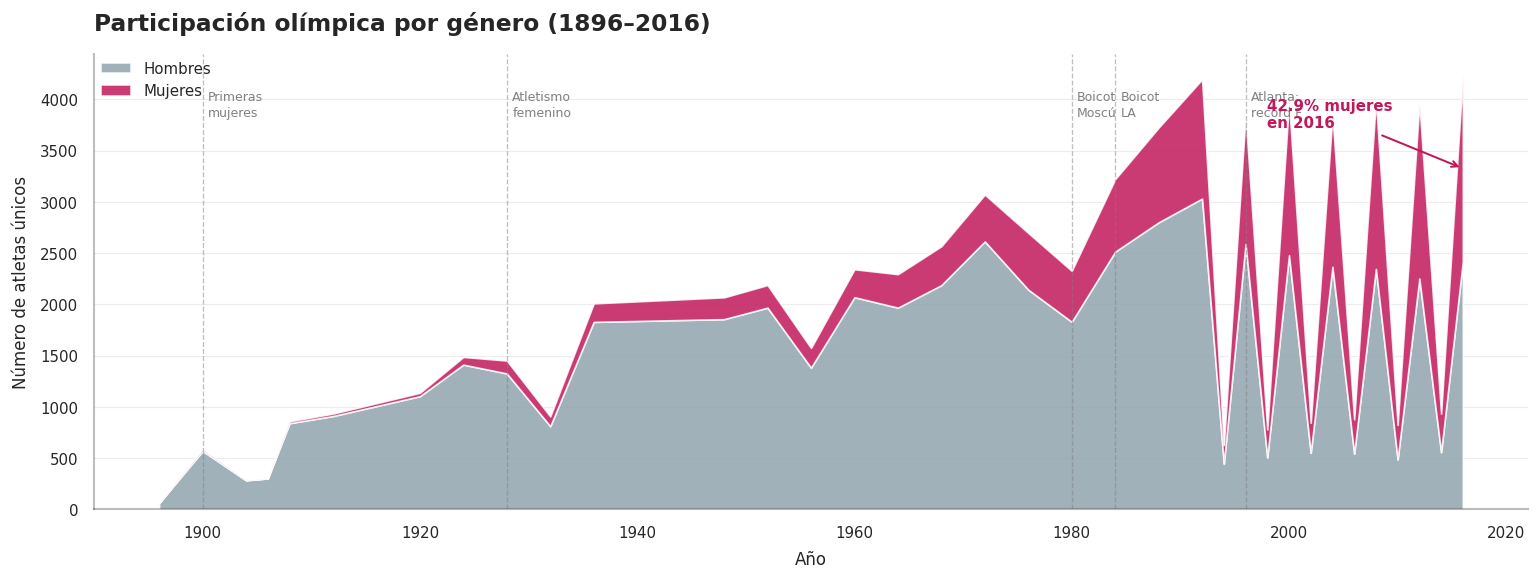

In [58]:
# Visualización 1 — Matplotlib / Seaborn
# Pregunta: ¿Cómo ha cambiado la participación de mujeres en los JJ.OO. a lo largo de la historia?

# ── 1. Preparación de datos ──────────────────────────────────────────────────

# Contamos atletas ÚNICOS por año y sexo (un atleta puede aparecer en varios eventos)
participacion = (
    df.dropna(subset=["Sex"])                        # eliminamos filas sin sexo registrado
      .groupby(["Year", "Sex"])["Name"]              # agrupamos por año y género
      .nunique()                                     # conteo de nombres únicos (evita duplicar por evento)
      .reset_index(name="Atletas")                   # convertimos a DataFrame limpio
)

# Separamos hombres y mujeres en columnas separadas para el área apilada
pivot = participacion.pivot(index="Year", columns="Sex", values="Atletas").fillna(0)
# fillna(0): años sin mujeres registradas quedan en 0, no en NaN

# Calculamos el porcentaje femenino para anotarlo en el gráfico
pivot["%F"] = pivot["F"] / (pivot["F"] + pivot["M"]) * 100

# ── 2. Configuración visual ──────────────────────────────────────────────────

# Paleta con significado: coral para mujeres (calidez, visibilidad), azul acero para hombres (contraste)
# No usamos colores de género estereotipados (rosa/azul claro) — elegimos contraste funcional
COLOR_F = "#C2185B"   # coral oscuro — línea principal que queremos que el ojo vea primero
COLOR_M = "#90A4AE"   # gris azulado — contexto, recesivo intencionalmente

fig, ax = plt.subplots(figsize=(13, 5))

# ── 3. Área apilada ──────────────────────────────────────────────────────────

years = pivot.index.values

# Área de hombres (base): color recesivo, alfa bajo — es contexto, no el mensaje principal
ax.stackplot(years, pivot["M"], pivot["F"],
             labels=["Hombres", "Mujeres"],
             colors=[COLOR_M, COLOR_F],
             alpha=0.85)

# ── 4. Ratio datos-tinta: eliminamos todo lo que no aporta información ────────

ax.spines["top"].set_visible(False)      # borde superior → eliminar
ax.spines["right"].set_visible(False)    # borde derecho  → eliminar
ax.spines["left"].set_alpha(0.3)         # borde izquierdo → suavizar (casi invisible)
ax.spines["bottom"].set_alpha(0.3)       # borde inferior  → suavizar

ax.yaxis.grid(True, color="gray", alpha=0.15, linewidth=0.7)  # cuadrícula muy tenue
ax.xaxis.grid(False)                                           # sin cuadrícula vertical (innecesaria)
ax.set_axisbelow(True)                   # la cuadrícula queda detrás de las áreas

# ── 5. Jerarquía visual: anotaciones sobre eventos históricos clave ───────────

# Líneas verticales en hitos históricos — guían la lectura sin saturar
hitos = {
    1900: "Primeras\nmujeres",
    1928: "Atletismo\nfemenino",
    1980: "Boicot\nMoscú",
    1984: "Boicot\nLA",
    1996: "Atlanta:\nrecord F",
}

for year, label in hitos.items():
    if year in pivot.index:
        ax.axvline(year, color="gray", linewidth=0.8, linestyle="--", alpha=0.5)
        ax.text(year + 0.5, ax.get_ylim()[1] * 0.92 if ax.get_ylim()[1] > 0 else 6000,
                label, fontsize=7.5, color="gray", va="top", ha="left", linespacing=1.3)

# Anotación del porcentaje en el último año disponible (jerarquía: dato más relevante destacado)
ultimo_año = pivot.index[-1]
pct_final = pivot.loc[ultimo_año, "%F"]
ax.annotate(
    f"{pct_final:.1f}% mujeres\nen {ultimo_año}",
    xy=(ultimo_año, pivot.loc[ultimo_año, "F"] / 2 + pivot.loc[ultimo_año, "M"]),
    xytext=(ultimo_año - 18, pivot.loc[ultimo_año, ["M","F"]].sum() * 0.88),
    fontsize=9, color=COLOR_F, fontweight="bold",
    arrowprops=dict(arrowstyle="->", color=COLOR_F, lw=1.2)
)

# ── 6. Títulos y etiquetas ───────────────────────────────────────────────────

ax.set_title(
    "Participación olímpica por género (1896–2016)",
    fontsize=14, fontweight="bold", pad=14, loc="left"   # alineado a la izquierda: más periodístico
)
ax.set_xlabel("Año", fontsize=10, labelpad=6)
ax.set_ylabel("Número de atletas únicos", fontsize=10, labelpad=6)
ax.tick_params(axis="both", labelsize=9)

# Leyenda posicionada en la esquina superior izquierda para no tapar el área femenina (pequeña al inicio)
ax.legend(loc="upper left", fontsize=9, framealpha=0, borderpad=0)

plt.tight_layout()
plt.show()

### Historia / mensaje de la Viz 1

- **¿Qué muestra el gráfico?** La participación femenina en los Juegos Olímpicos
  pasó de ser prácticamente inexistente en 1896 a representar el 42.9% de los
  atletas en 2016, con aceleraciones visibles tras hitos como la inclusión del
  atletismo femenino en 1928 y un crecimiento sostenido desde los años 80.

- **¿Por qué es relevante?** Los picos y caídas abruptas que aparecen a partir
  de 1990 reflejan la separación entre Juegos de Verano e Invierno (desde 1994
  se celebran en años distintos), lo que visualmente puede confundirse con
  volatilidad real en la participación; entender esa causa estructural evita
  interpretaciones erróneas del dato.

- **¿Qué decisión o acción sugiere?** Si el objetivo de un análisis posterior
  es comparar tendencias de género de forma limpia, conviene filtrar por
  `Season == 'Summer'` o `Season == 'Winter'` por separado, ya que mezclar
  ambas temporadas en un mismo eje temporal distorsiona la lectura de la
  evolución histórica.


---
## 6. Visualización 2 — Plotly

**Pregunta:** *¿Qué países dominan ciertos deportes olímpicos y cuánto concentran las medallas de oro?*

### Lo que la interactividad debe agregar

La interactividad de Plotly no es un fin en sí mismo.
Pregúntate: ¿qué puede descubrir el usuario al hacer hover o zoom
que no podría ver en un gráfico estático?

Si la respuesta es "nada", el gráfico no necesita ser interactivo.

Configura el hover para que muestre exactamente la información
que responde la pregunta. Nada más, nada menos.


In [59]:
# Visualización 2 — Plotly Express
# Pregunta: ¿Qué países dominan ciertos deportes olímpicos y cuánto concentran las medallas?

# ── 1. Preparación de datos ──────────────────────────────────────────────────

# Filtramos solo filas con medalla registrada (la mayoría del dataset son no-medallistas)
medallas = df[df["Medal"].notna()].copy()

# Contamos medallas por país y deporte
# Usamos Name para contar atletas medallistas únicos (evita doble conteo en deportes de equipo)
conteo = (
    medallas
    .groupby(["NOC", "Team", "Sport", "Medal"])["Name"]
    .nunique()
    .reset_index(name="Count")
)

# Agrupamos por país + deporte (sin distinguir tipo de medalla) para el tamaño del treemap
por_pais_deporte = (
    conteo
    .groupby(["NOC", "Team", "Sport"])["Count"]
    .sum()
    .reset_index()
)

# Agrupamos también a nivel país para el nivel superior del treemap
por_pais = (
    por_pais_deporte
    .groupby(["NOC", "Team"])["Count"]
    .sum()
    .reset_index()
)

# Solo los top 20 países por total de medallas (el treemap con 200 países es ilegible)
top20_noc = por_pais.nlargest(20, "Count")["NOC"].tolist()
por_pais_deporte_top = por_pais_deporte[por_pais_deporte["NOC"].isin(top20_noc)]

# Columna de texto para el hover: "País · Deporte"
por_pais_deporte_top = por_pais_deporte_top.copy()
por_pais_deporte_top["label"] = por_pais_deporte_top["Team"] + " — " + por_pais_deporte_top["Sport"]

# ── 2. Construcción del treemap ──────────────────────────────────────────────

fig = px.treemap(
    por_pais_deporte_top,
    path=["NOC", "Sport"],          # jerarquía: nivel 1 = país, nivel 2 = deporte
    values="Count",                  # tamaño de cada tile = número de atletas medallistas
    color="Count",                   # color secuencial por conteo (más oscuro = más medallas)
    color_continuous_scale="Blues",  # paleta secuencial: azul claro → azul oscuro
                                     # justificación: es una variable de intensidad, no categórica
    hover_data={"NOC": True, "Sport": True, "Count": True},
    title="Concentración de medallas olímpicas por país y deporte (top 20 países, 1896–2016)"
)

# ── 3. Configuración del hover ───────────────────────────────────────────────
# El hover muestra EXACTAMENTE lo que responde la pregunta:
# qué país, en qué deporte, cuántas medallas — nada más

fig.update_traces(
    hovertemplate=(
        "<b>%{label}</b><br>"
        "Atletas medallistas: <b>%{value}</b><br>"
        "<extra></extra>"          # elimina el bloque secundario que Plotly agrega por defecto
    ),
    textinfo="label+value",        # dentro de cada tile: nombre + número
    textfont_size=12,
)

# ── 4. Diseño: ratio datos-tinta ─────────────────────────────────────────────

fig.update_layout(
    title=dict(
        text="Concentración de medallas olímpicas por país y deporte<br>"
             "<sup>Top 20 países · 1896–2016 · Atletas medallistas únicos</sup>",
        font=dict(size=15),
        x=0,                        # alineado a la izquierda
        xanchor="left"
    ),
    margin=dict(t=70, l=10, r=10, b=10),   # márgenes mínimos — el treemap ocupa todo el espacio
    coloraxis_showscale=False,              # eliminamos la barra de color: el tamaño ya codifica
                                            # la magnitud; la barra sería redundante (ratio datos-tinta)
    paper_bgcolor="white",
    font=dict(family="Arial, sans-serif", size=11),
    height=580
)

fig.show()

### Historia / mensaje de la Viz 2

- **¿Qué muestra el gráfico?** El treemap revela una concentración extrema del
  éxito olímpico: USA domina el mapa con 403 atletas medallistas solo en
  atletismo y 279 en natación, mientras que países como GBR, GER y URS
  distribuyen sus medallas de forma más diversificada entre deportes como
  remo, hockey y gimnasia. El tamaño de cada tile hace visible de un vistazo
  una desigualdad que una tabla de números nunca comunicaría con la misma
  fuerza.

- **¿Qué descubre el usuario al interactuar con él?** Al hacer clic en un país
  el usuario navega al nivel de deporte y encuentra especializaciones que son
  invisibles en la vista general: CAN concentra sus medallas en hockey sobre
  hielo (108) más que en cualquier otro deporte, NOR tiene una presencia
  desproporcionada en vela y biatlón dado su tamaño poblacional, y FRA lidera
  en esgrima (112) por encima de atletismo. Esas especializaciones culturales
  e históricas solo emergen al explorar el segundo nivel del treemap.

- **¿Qué decisión o acción sugiere?** Para un análisis más justo entre países,
  conviene normalizar las medallas por población o por número de ediciones
  participadas, ya que el tamaño absoluto favorece sistemáticamente a las
  potencias con mayor historia olímpica. Un siguiente paso natural sería
  filtrar por `Season` o por rango de años para ver si la dominancia de
  ciertos países cambia entre la era de la Guerra Fría y la era moderna.

---
## 7. Visualización 3 — Altair

**Pregunta:** *¿Existe una relación entre el perfil físico (altura / peso) y el deporte practicado?*


In [60]:
# Visualización 3 — Altair (versión sin vegafusion, muestra estratificada)
# Pregunta: ¿Existe una relación entre el perfil físico (altura/peso) y el deporte practicado?

# ── 1. Preparación de datos ──────────────────────────────────────────────────
df_fisico = df.dropna(subset=["Height", "Weight", "Sport", "Sex"]).copy()

top_deportes = (
    df_fisico.groupby("Sport")["Name"]
    .nunique()
    .nlargest(10)
    .index.tolist()
)
df_top = df_fisico[df_fisico["Sport"].isin(top_deportes)].copy()

df_top["IMC"]       = (df_top["Weight"] / (df_top["Height"] / 100) ** 2).round(1)
df_top["Medallista"] = df_top["Medal"].notna().map({True: "Sí", False: "No"})

# Un atleta único por Name+Sport
df_unico = (
    df_top
    .drop_duplicates(subset=["Name", "Sport"])
    .reset_index(drop=True)
)

# ── 2. Muestra estratificada por deporte (máx 4500 filas, <5000 límite Altair) ──
# Cada deporte aporta filas proporcionales a su tamaño real
# Muestra estratificada — fix para deprecation warning de pandas
df_plot = (
    df_unico
    .groupby("Sport", group_keys=False)[df_unico.columns]  # selección explícita de columnas
    .apply(lambda g: g.sample(
        n=min(len(g), max(1, int(4500 * len(g) / len(df_unico)))),
        random_state=42
    ))
    .reset_index(drop=True)
)

# ── 3. Medias por deporte (para los diamantes de referencia) ─────────────────

medias = (
    df_unico                                  # usamos df_unico completo, no la muestra
    .groupby("Sport")[["Height", "Weight"]]
    .mean()
    .round(1)
    .reset_index()
    .rename(columns={"Height": "mean_h", "Weight": "mean_w"})
)

# ── 4. Selección interactiva ─────────────────────────────────────────────────

seleccion = alt.selection_point(fields=["Sport"], bind="legend")

paleta = alt.Scale(
    domain=top_deportes,
    range=[
        "#2a78d6", "#1baf7a", "#eda100", "#e34948",
        "#4a3aa7", "#e87ba4", "#eb6834", "#008300",
        "#90A4AE", "#C2185B"
    ]
)

# ── 5. Scatter ───────────────────────────────────────────────────────────────

scatter = (
    alt.Chart(df_plot)
    .mark_circle(size=45, stroke="white", strokeWidth=0.5)
    .encode(
        x=alt.X("Height:Q", title="Altura (cm)",
                scale=alt.Scale(zero=False),
                axis=alt.Axis(grid=True, gridOpacity=0.15, tickCount=8)),
        y=alt.Y("Weight:Q", title="Peso (kg)",
                scale=alt.Scale(zero=False),
                axis=alt.Axis(grid=True, gridOpacity=0.15, tickCount=8)),
        color=alt.condition(
            seleccion,
            alt.Color("Sport:N", scale=paleta,
                      legend=alt.Legend(
                          title="Deporte (clic para filtrar)",
                          orient="right",
                          symbolSize=80,
                          labelFontSize=11,
                          titleFontSize=11
                      )),
            alt.value("#e0e0e0")
        ),
        opacity=alt.condition(seleccion, alt.value(0.75), alt.value(0.08)),
        tooltip=[
            alt.Tooltip("Name:N",       title="Atleta"),
            alt.Tooltip("Sport:N",      title="Deporte"),
            alt.Tooltip("Height:Q",     title="Altura (cm)"),
            alt.Tooltip("Weight:Q",     title="Peso (kg)"),
            alt.Tooltip("IMC:Q",        title="IMC"),
            alt.Tooltip("Sex:N",        title="Sexo"),
            alt.Tooltip("Medallista:N", title="Medallista"),
        ]
    )
    .add_params(seleccion)
    .properties(width=620, height=420)
)

# ── 6. Diamantes de media ────────────────────────────────────────────────────

puntos_media = (
    alt.Chart(medias)
    .mark_point(shape="diamond", size=150, filled=True,
                stroke="white", strokeWidth=1.2)
    .encode(
        x="mean_h:Q",
        y="mean_w:Q",
        color=alt.Color("Sport:N", scale=paleta, legend=None),
        opacity=alt.condition(seleccion, alt.value(1.0), alt.value(0.1)),
        tooltip=[
            alt.Tooltip("Sport:N",  title="Deporte"),
            alt.Tooltip("mean_h:Q", title="Altura media (cm)", format=".1f"),
            alt.Tooltip("mean_w:Q", title="Peso medio (kg)",   format=".1f"),
        ]
    )
    .add_params(seleccion)
)

# ── 7. Composición final ─────────────────────────────────────────────────────

chart = (
    (scatter + puntos_media)
    .properties(
        title=alt.TitleParams(
            text="Perfil físico de atletas olímpicos por deporte (top 10)",
            subtitle=[
                "Cada punto es un atleta único · Los diamantes marcan la media del deporte",
                "Clic en la leyenda para filtrar · Shift+clic para seleccionar varios deportes"
            ],
            fontSize=14,
            subtitleFontSize=11,
            subtitleColor="#666666",
            anchor="start"
        )
    )
    .configure_view(strokeWidth=0)
    .configure_axis(
        labelFontSize=10,
        titleFontSize=11,
        domainColor="#cccccc",
        tickColor="#cccccc"
    )
    .configure_legend(padding=10, cornerRadius=4)
)
display(chart)

alt.LayerChart(...)

### Historia / mensaje de la Viz 3

- **¿Qué muestra el gráfico?** El gráfico muestra la relación entre la altura y el peso de atletas olímpicos pertenecientes a los diez deportes con mayor número de participantes. Cada punto representa un atleta y los diamantes indican la altura y el peso promedio de cada deporte.

- **¿Qué permite descubrir la interacción?**
La interacción mediante la leyenda y los tooltips permite filtrar uno o varios deportes, comparar sus perfiles físicos y explorar la información individual de cada atleta, identificando similitudes, diferencias y posibles valores atípicos.
- **¿Qué decisión o acción sugiere?**El análisis evidencia que cada deporte presenta un perfil físico característico, por lo que la altura y el peso son variables relevantes para comparar disciplinas. Esta información puede apoyar estudios sobre selección de atletas, preparación física o análisis del rendimiento según las exigencias de cada deporte.


---
## Checklist de entrega

| Criterio | Descripción | Listo |
|---|---|---|
| Formato | Archivo único `.ipynb` | [ ] |
| Ejecución | Corre de principio a fin sin errores | [ ] |
| Dataset | Celda con la elección y la razón | [ ] |
| EDA | Nulos, descriptivas, categóricas y limpieza documentados | [ ] |
| Prompt | Prompt original pegado sin modificar | [ ] |
| Estrategia | Tres gráficos seleccionados con pregunta y justificación | [ ] |
| Viz 1 | Matplotlib/Seaborn con principios de diseño aplicados | [ ] |
| Viz 2 | Plotly con hover configurado para responder la pregunta | [ ] |
| Viz 3 | Altair con al menos un elemento de interacción | [ ] |
| Narrativa | Historia escrita debajo de cada visualización | [ ] |

---
*Bootcamp Python PY4 · Módulo 1 · Semana 4 · Kodigo Academia de Tecnología Creativa*
